# 1. Transmission: Kirchhoff flows and I²R losses

**Transmission poles** are the poles Power Overload rates like a big pole or more: the big and
huge transmission poles, their fuses, and other mods' poles at that rating. They have no supply
area: they only carry power, and transformers step it down to distribution poles (notebook 2).
The model below applies to an electric network made only of transmission poles. One
distribution pole in it, or a generator feeding a transformer from it, makes the whole network
distribution; the pole window then says so.
On them, the mod does not pick a route for the power. It solves where the power goes, the way
current divides in a circuit:

* Every transformer output **injects** the power it delivers; every transformer input, and every
  machine load, **draws**. These come from the game's measurements.
* Wire cost (length × mean resistance of its two poles) plays the **resistance**. At each node
  the power in equals the power out (Kirchhoff's current law), which gives a linear system
  `G·V = P` (`G`: conductances 1/cost, `P`: injections). `V` is a potential the solver uses;
  it is not a voltage in the game. The flow on a wire is `(V_a − V_b) / cost`.
* Parallel routes therefore share power inversely to their resistance.

Each wire then loses power in proportion to its load (**I²R**):

$$\text{share lost} = 0.025\% \times \text{cost} \times \left(0.1 + 0.9\,\frac{\text{flow}}{P_\text{ref}}\right), \qquad P_\text{ref} = \tfrac14 \times \text{rating of the wire's weaker pole}$$

At a quarter of its rating a wire loses the plain 0.025% per tile; below that less, above that
more, up to 3.7 times at full rating. The 10% floor is a share of the flow: an idle wire loses
nothing, a lightly loaded one a little. The reference grows with the rating, the way a
higher-voltage line loses less per MW.
A transformer pays for the losses on the power it supplies; one fed through transmission shows,
as its upstream line loss, the loss per unit of power reaching its input.

This is the "DC power flow" approximation grid operators use for quick studies: no voltage drop,
no reactive power, losses computed from the flows afterwards. `lineloss_model.py` mirrors the
mod's code; on the testbench layouts it gives the mod's numbers to four decimals.

Three examples:
1. Two parallel lines of different pole types
2. A bottleneck, and a bypass around it (testbench `/ll-bottleneck`)
3. A meshed grid with three consumers, one a medium-pole block (testbench `/ll-flows`)

In [1]:
import math
import os

import numpy as np
import matplotlib.pyplot as plt

import lineloss_model as m

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})


def draws_settled(poles, wires, outputs_fn, inputs_fn, machines, rounds=5):
    """Transformer draws depend on their own downstream losses: iterate a few times."""
    extra = {}
    for _ in range(rounds):
        r = m.solve(poles, wires, outputs_fn(extra), inputs_fn(extra), machines)
        extra = r["burn"]
    return r

## The loss rule

100 tiles of line, from no load to each pole's rating. Fuses behave like their pole. Big
transmission poles: resistance 1 per tile, rating 300 MW, reference 75 MW. Huge transmission
poles: resistance 0.32, rating 3 GW, reference 750 MW.

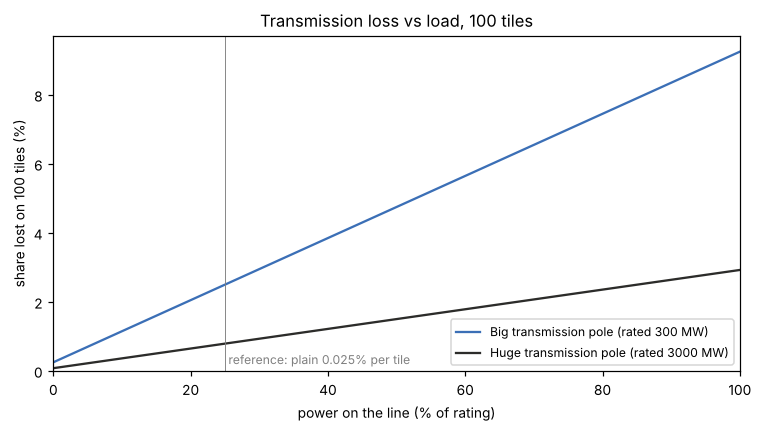

In [2]:
os.makedirs("gallery", exist_ok=True)
POLES = (("Big transmission pole", 1.0, 300e6, "#3b6fb6"),
         ("Huge transmission pole", m.resistance("huge"), 3e9, "#2c2c2a"))


pct = np.linspace(0, 100, 201)
fig, ax = plt.subplots(figsize=(7, 4))
for name, r, rating, col in POLES:
    ax.plot(pct, [100 * m.i2r_share(100 * r, p / 100 * rating, rating) for p in pct], color=col,
            label=f"{name} (rated {rating / 1e6:g} MW)")
ax.axvline(100 * m.REF_SHARE, color="grey", lw=0.6)
ax.text(100 * m.REF_SHARE, 0.2, " reference: plain 0.025% per tile", fontsize=8, color="grey")
ax.set_xlabel("power on the line (% of rating)")
ax.set_ylabel("share lost on 100 tiles (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0)
ax.legend(fontsize=8)
ax.set_title("Transmission loss vs load, 100 tiles")
plt.tight_layout()
plt.savefig("gallery/transmission_loss_share.png", dpi=150)
plt.show()

The share lost rises in a straight line with the load. The power lost is that share times the
load, so it grows with the square of the load: doubling the load quadruples the loss.

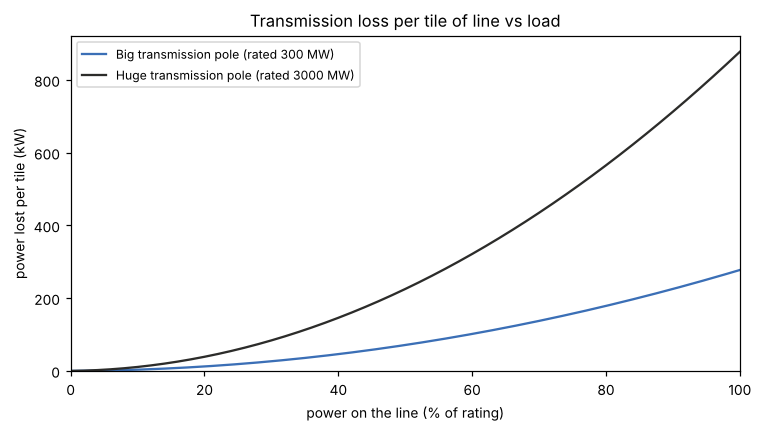

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, r, rating, col in POLES:
    ax.plot(pct, [p / 100 * rating * m.i2r_share(r, p / 100 * rating, rating) / 1e3 for p in pct], color=col,
            label=f"{name} (rated {rating / 1e6:g} MW)")
ax.set_xlabel("power on the line (% of rating)")
ax.set_ylabel("power lost per tile (kW)")
ax.set_xlim(0, 100)
ax.set_ylim(0)
ax.legend(fontsize=8)
ax.set_title("Transmission loss per tile of line vs load")
plt.tight_layout()
plt.savefig("gallery/transmission_loss_per_tile.png", dpi=150)
plt.show()

Loss over a whole line, for a quarter (the reference) and half of the pole's rating delivered.
Wires at full reach (big 30 tiles, huge 64). As in the mod, every wire carries the same flow
(flows are solved without losses) and each wire's share compounds on the power after it. As a
share of what leaves the near end, the loss grows slightly less than the distance. A line cannot deliver its full rating: the
losses come on top, so the near end would pass the rating and overload.

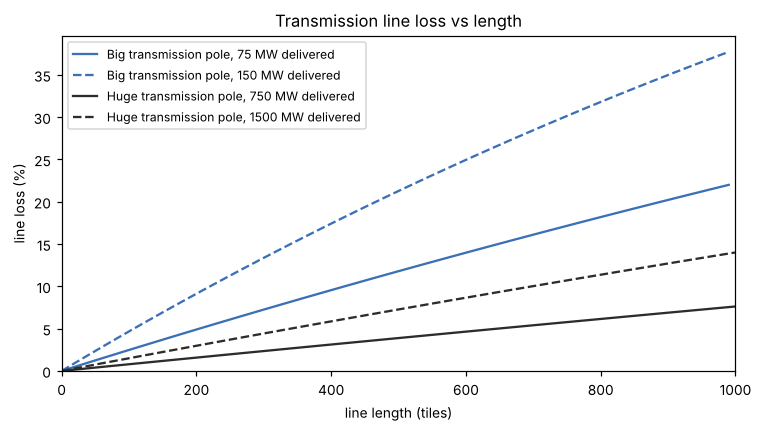

100 tiles of big line: 150 MW loses 7.1 MW; 300 MW loses 27.8 MW; two lines at 150 MW each lose 14.3 MW together


In [4]:
def line_loss(r, rating, delivered, tiles, wire):
    """Share lost over `tiles` of line, `delivered` W on every wire (as the mod: flows are
    solved without losses; each wire's share compounds on the power after it)."""
    rate = 0.0                     # power lost per unit delivered
    for _ in range(int(round(tiles / wire))):
        rr = m.ratio(m.i2r_share(wire * r, delivered, rating))
        rate = rr + rate * (1 + rr)
    return m.from_ratio(rate), delivered * (1 + rate)


fig, ax = plt.subplots(figsize=(7, 4))
for name, r, rating, col in POLES:
    wire = 30 if rating < 1e9 else 64
    for frac, ls in ((0.25, "-"), (0.5, "--")):
        xs, ys = [], []
        for tiles in list(range(0, 1001, wire)) + [round(1000 / wire) * wire]:
            loss, sent = line_loss(r, rating, frac * rating, tiles, wire)
            if sent > rating * 1.0001:
                ax.plot(xs[-1], ys[-1], "x", color=col)
                break
            xs.append(tiles); ys.append(100 * loss)
        ax.plot(xs, ys, color=col, ls=ls, label=f"{name}, {frac * rating / 1e6:g} MW delivered")
ax.set_xlabel("line length (tiles)")
ax.set_ylabel("line loss (%)")
ax.set_xlim(0, 1000)
ax.set_ylim(0)
ax.legend(fontsize=8)
ax.set_title("Transmission line loss vs length")
plt.tight_layout()
plt.savefig("gallery/transmission_loss_vs_tiles.png", dpi=150)
plt.show()

big = lambda f: f * m.i2r_share(100, f, 300e6) / 1e6
print(f"100 tiles of big line: 150 MW loses {big(150e6):.1f} MW; 300 MW loses {big(300e6):.1f} MW; "
      f"two lines at 150 MW each lose {2 * big(150e6):.1f} MW together")

Light lines are cheap, busy lines expensive. Two lines sharing a load lose about half of what
one line carrying it all would.

## Example 1: two parallel lines

T1 sends 100 MW to T2, 120 tiles away, over two lines: big transmission poles (south, resistance
1 per tile) and huge transmission poles (north, 0.32 per tile). The huge line itself has a third of the
resistance, but the two 26-tile wires joining it to the big poles at A and B cost the average of
both poles, so the north route costs about 72 against 118: it takes 62% of the power, the share
the inverse-resistance rule gives.

route costs: north (huge) 71.5, south (big transmission) 118.0 tiles
flows: north 63.0 MW, south 38.2 MW -> north share 0.623, inverse-resistance rule 0.623
T1 downstream line loss 1.320%, T2 upstream 1.320%


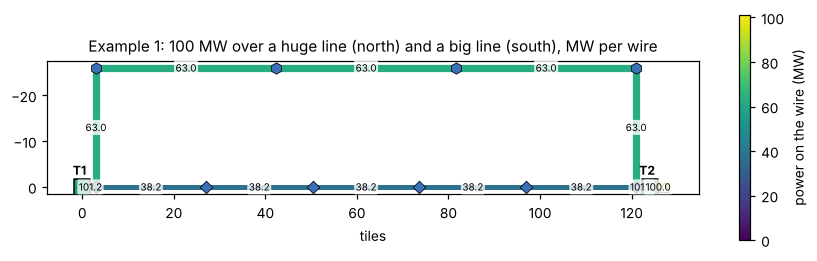

In [5]:
def two_lines(with_huge=True, with_big=True):
    poles, wires = {}, []
    t1i, t1o = m.transformer(poles, "T1", 0, 0)
    t2i, t2o = m.transformer(poles, "T2", 124, 0)
    poles["A"] = (3, 0, "big")
    poles["B"] = (121, 0, "big")
    wires += [(t1o, "A"), ("B", t2i)]
    if with_big:
        m.line(poles, wires, "s", (27, 0), (97, 0), 4, "big", first="A", last="B")
    if with_huge:
        m.line(poles, wires, "h", (3, -26), (121, -26), 4, "huge", first="A", last="B")
    poles["L"] = (127, 0, "substation")     # T2's consumers, on a substation
    wires.append((t2o, "L"))
    return poles, wires, t1o, t2i, t2o


def run_two_lines(load, **kw):
    poles, wires, t1o, t2i, t2o = two_lines(**kw)
    draw2 = lambda extra: (load + extra.get(t2o, 0)) / m.EFFICIENCY + m.CORE_LOSS * 125e6
    r = draws_settled(poles, wires, lambda e: {t1o: draw2(e), t2o: load}, lambda e: {t2i: draw2(e)},
                      {"L": load})
    return poles, wires, r, t1o, t2i


poles, wires, r, t1o, t2i = run_two_lines(100e6)
north = r["flow"][m.key("A", "h0")]
south = r["flow"][m.key("A", "s0")]
cost = lambda names: sum(m.wire_cost(poles, a, b) for a, b in zip(names, names[1:]))
c_n = cost(["A", "h0", "h1", "h2", "h3", "B"])
c_s = cost(["A", "s0", "s1", "s2", "s3", "B"])
print(f"route costs: north (huge) {c_n:.1f}, south (big transmission) {c_s:.1f} tiles")
print(f"flows: north {north / 1e6:.1f} MW, south {south / 1e6:.1f} MW "
      f"-> north share {north / (north + south):.3f}, inverse-resistance rule {c_s / (c_n + c_s):.3f}")
print(f"T1 downstream line loss {r['down'][t1o]:.3%}, T2 upstream {r['up'][t2i]:.3%}")

fig, ax = plt.subplots(figsize=(8, 3))
m.draw(ax, poles, wires, r, title="Example 1: 100 MW over a huge line (north) and a big line (south), MW per wire")
plt.tight_layout()
plt.show()

Huge poles are rated 3 GW, so their wires lose little at this load: the reference is
750 MW. Most of the loss is on the big-pole line and on the short big-pole wires at either end,
which carry all 100 MW.

How the loss grows with load, for each line alone and for both together:

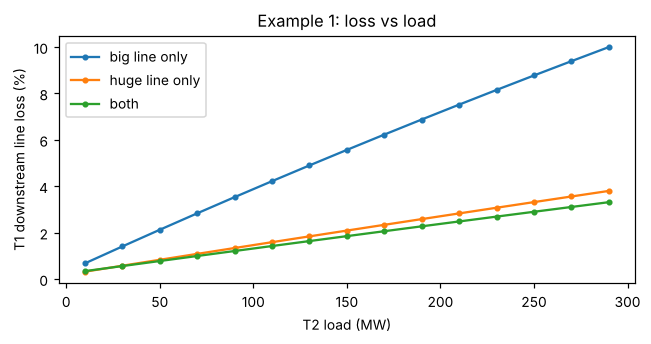

In [6]:
loads = np.linspace(10e6, 290e6, 15)
cases = {"big line only": dict(with_huge=False), "huge line only": dict(with_big=False),
         "both": {}}
fig, ax = plt.subplots(figsize=(6, 3.2))
for name, kw in cases.items():
    ys = []
    for L in loads:
        _, _, rr, o, _ = run_two_lines(L, **kw)
        ys.append(100 * rr["down"][o])
    ax.plot(loads / 1e6, ys, marker=".", label=name)
ax.set_xlabel("T2 load (MW)")
ax.set_ylabel("T1 downstream line loss (%)")
ax.set_title("Example 1: loss vs load")
ax.legend()
plt.tight_layout()
plt.show()

Every curve rises with the load (I²R). Adding the huge line to the big one cuts the loss to a
fraction: the power moves to the low-resistance line, and the big line carries less.

## Example 2: a bottleneck, and a bypass

The testbench's `/ll-bottleneck` layout: T1 splits into two branches that merge into a single
line C1-C2-C3 (two 30-tile wires), then split again to reach T2 and its 260 MW load. Every
megawatt goes through the chokepoint.

(In game, 260 MW on one distribution network exceeds a substation's 125 MW under Power
Overload's default overload check: T2 would be several transformers feeding separate networks,
or Power Overload's check set to Nothing so poles overload on the power through them. The
transmission side, which is what this example is about, is the same either way.)

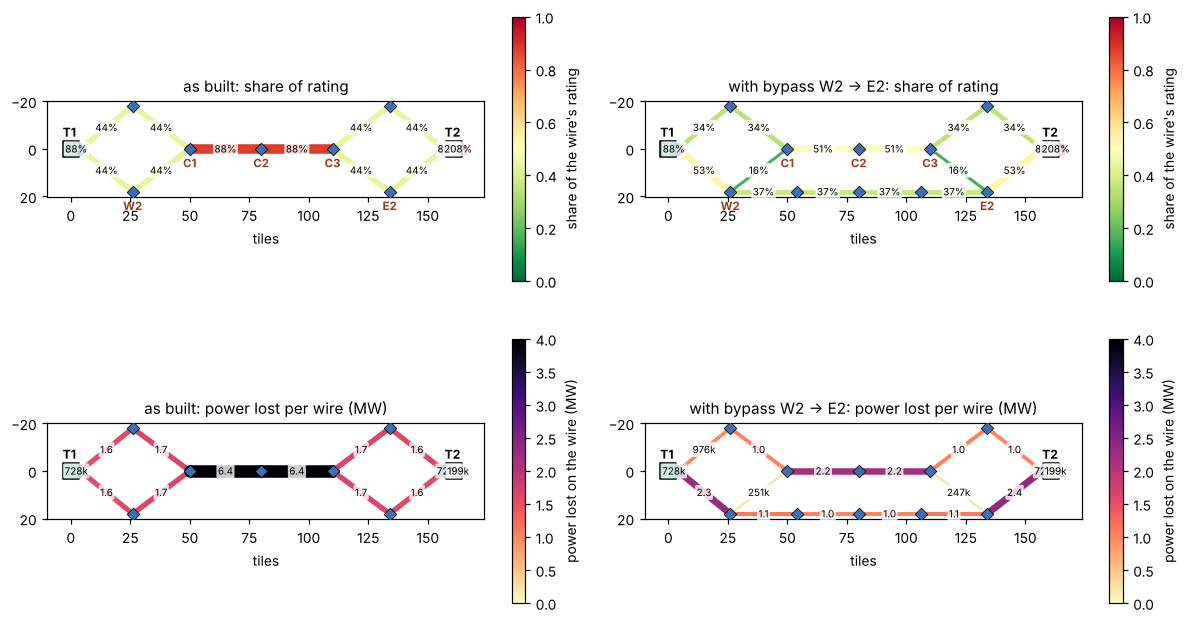

as built : chokepoint  263.0 MW (88% of rating), lost on it 12.84 MW, T1 line loss 9.40% (27.3 MW)
bypass   : chokepoint  151.7 MW (51% of rating), lost on it 4.37 MW, T1 line loss 6.85% (19.3 MW)


In [7]:
def bottleneck(bypass=False, load=260e6):
    poles, wires = {}, []
    t1i, t1o = m.transformer(poles, "T1", 0, 0)
    t2i, t2o = m.transformer(poles, "T2", 161, 0)
    pts = {"A": (4, 0), "W1": (26, -18), "W2": (26, 18), "C1": (50, 0), "C2": (80, 0), "C3": (110, 0),
           "E1": (134, -18), "E2": (134, 18), "D": (157, 0)}
    for n, (x, y) in pts.items():
        poles[n] = (x, y, "big")
    wires += [(t1o, "A"), ("A", "W1"), ("A", "W2"), ("W1", "C1"), ("W2", "C1"), ("C1", "C2"),
              ("C2", "C3"), ("C3", "E1"), ("C3", "E2"), ("E1", "D"), ("E2", "D"), ("D", t2i)]
    if bypass:
        m.line(poles, wires, "y", (54, 18), (106, 18), 3, "big", first="W2", last="E2")
    poles["L"] = (164, 0, "substation")
    wires.append((t2o, "L"))
    draw2 = lambda e: (load + e.get(t2o, 0)) / m.EFFICIENCY + m.CORE_LOSS * 125e6
    r = draws_settled(poles, wires, lambda e: {t1o: draw2(e), t2o: load}, lambda e: {t2i: draw2(e)},
                      {"L": load})
    return poles, wires, r, t1o


results = {}
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
for col, bypass in enumerate((False, True)):
    poles, wires, r, t1o = bottleneck(bypass)
    results[bypass] = (r, t1o)
    tag = "with bypass W2 -> E2" if bypass else "as built"
    m.draw(axes[0, col], poles, wires, r, value="loading", vmax=1.0, cmap="RdYlGn_r", labels="loading",
           title=f"{tag}: share of rating", names={n: n for n in ("C1", "C2", "C3", "W2", "E2")})
    m.draw(axes[1, col], poles, wires, r, value="lost", vmax=4e6, cmap="magma_r", labels="lost",
           title=f"{tag}: power lost per wire (MW)")
plt.tight_layout()
plt.show()
for bypass, (r, t1o) in results.items():
    choke = r["flow"][m.key("C1", "C2")]
    print(f"{'bypass' if bypass else 'as built':9s}: chokepoint {choke / 1e6:6.1f} MW ({choke / 300e6:.0%} of rating), "
          f"lost on it {sum(r['lost'][m.key(a, b)] for a, b in (('C1', 'C2'), ('C2', 'C3'))) / 1e6:.2f} MW, "
          f"T1 line loss {r['down'][t1o]:.2%} ({r['burn'][t1o] / 1e6:.1f} MW)")

The bypass takes about 40% of the power off the chokepoint: from 88% of its rating to about
50%. Since loss grows with load × length, that wire's loss drops by more than half, and the bypass
adds only a little of its own. T1's line loss falls by about a third (figures below the maps).

Reading the two views together: a wire that is red in **Line loading (% of rating)** and in
**Line losses** is a true chokepoint. A parallel path there pays twice: less loss, and no
overload risk.

## Example 3: a meshed grid with a distribution block

The testbench's `/ll-flows` layout. From T1, three routes leave pole A: a huge-pole line north,
a straight line south (to B, then C), and a loop west and along the bottom through M (to C). T2
draws 60 MW at B and T3 40 MW at C. At M, T4 steps down to a medium-pole block carrying 30 MW of
machines (4 poles × 7.5 MW). The block is its own distribution network (notebook 2); the mesh
sees only T4's draw. Wiring the block straight to M instead would put a distribution pole in the
mesh and turn the whole network into distribution.

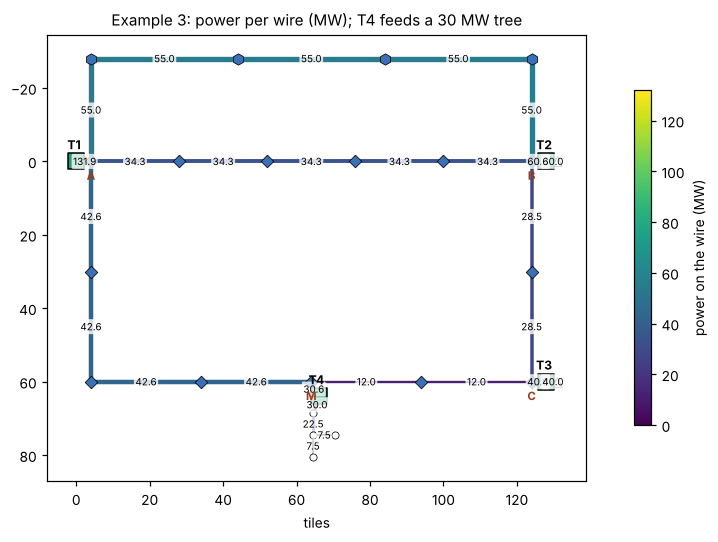

leaving A: {'north (huge)': 55.02, 'south': 34.3, 'west': 42.57} MW; total 131.89
T1 downstream line loss 1.70%; upstream: T2 1.31%, T3 2.05%, T4 1.98%; T4 downstream (tree) 0.62%
networks: ['distribution', 'transmission']


In [8]:
def mesh():
    poles, wires = {}, []
    t1i, t1o = m.transformer(poles, "T1", 0, 0)
    t2i, t2o = m.transformer(poles, "T2", 128, 0)
    t3i, t3o = m.transformer(poles, "T3", 128, 60)
    poles["A"] = (4, 0, "big")
    wires.append((t1o, "A"))
    s = m.line(poles, wires, "s", (28, 0), (124, 0), 5, "big", first="A")
    poles["B"] = poles.pop(s[-1]); wires[:] = [tuple("B" if x == s[-1] else x for x in w) for w in wires]
    h = m.line(poles, wires, "h", (4, -28), (124, -28), 4, "huge", first="A", last="B")
    c = m.line(poles, wires, "c", (124, 30), (124, 60), 2, "big", first="B")
    poles["C"] = poles.pop(c[-1]); wires[:] = [tuple("C" if x == c[-1] else x for x in w) for w in wires]
    w = m.line(poles, wires, "w", (4, 30), (4, 60), 2, "big", first="A")
    b = m.line(poles, wires, "b", (34, 60), (94, 60), 3, "big", first=w[-1], last="C")
    poles["M"] = poles.pop(b[1]); wires[:] = [tuple("M" if x == b[1] else x for x in w_) for w_ in wires]
    t4i, t4o = m.transformer(poles, "T4", 66, 64)
    tree = {"m1": (64.5, 68.5), "m2": (64.5, 74.5), "m3": (64.5, 80.5), "m4": (70.5, 74.5)}
    for n, (x, y) in tree.items():
        poles[n] = (x, y, "medium")
    wires += [("M", t4i), (t4o, "m1"), ("m1", "m2"), ("m2", "m3"), ("m2", "m4"), ("B", t2i), ("C", t3i)]
    poles["L2"] = (131, 0, "substation"); poles["L3"] = (131, 60, "substation")
    wires += [(t2o, "L2"), (t3o, "L3")]
    machines = {n: 7.5e6 for n in tree}
    machines.update({"L2": 60e6, "L3": 40e6})
    d2 = lambda e: (60e6 + e.get(t2o, 0)) / m.EFFICIENCY + m.CORE_LOSS * 125e6
    d3 = lambda e: (40e6 + e.get(t3o, 0)) / m.EFFICIENCY + m.CORE_LOSS * 125e6
    d4 = lambda e: (30e6 + e.get(t4o, 0)) / m.EFFICIENCY + m.CORE_LOSS * 60e6
    r = draws_settled(poles, wires, lambda e: {t1o: d2(e) + d3(e) + d4(e), t2o: 60e6, t3o: 40e6, t4o: 30e6},
                      lambda e: {t2i: d2(e), t3i: d3(e), t4i: d4(e)}, machines)
    return poles, wires, r, (t1o, t2i, t3i, t4i, t4o)


poles, wires, r, (t1o, t2i, t3i, t4i, t4o) = mesh()
fig, ax = plt.subplots(figsize=(9, 5))
m.draw(ax, poles, wires, r, title="Example 3: power per wire (MW); T4 feeds a 30 MW tree",
       names={"A": "A", "B": "B", "C": "C", "M": "M"})
plt.tight_layout()
plt.show()

out_of_A = {name: float(r["flow"][m.key("A", first)]) / 1e6 for name, first in
            (("north (huge)", "h0"), ("south", "s0"), ("west", "w0"))}
print("leaving A:", {k: round(v, 2) for k, v in out_of_A.items()}, "MW; total", round(sum(out_of_A.values()), 2))
print(f"T1 downstream line loss {r['down'][t1o]:.2%}; upstream: T2 {r['up'][t2i]:.2%}, T3 {r['up'][t3i]:.2%}, "
      f"T4 {r['up'][t4i]:.2%}; T4 downstream (tree) {r['down'][t4o]:.2%}")
print("networks:", sorted(set(r["network"].values())))

The north line has the lowest resistance and takes the most. B passes on what T2 does not need
to C, T4 takes its share at M, and C gets the rest from both sides for T3.

**Where each consumer's loss comes from.** Tracing down the flows, every node gets the loss per
unit of power reaching it: the loss of each wire on the way, averaged over the routes by the power
each brings. T2's input is reached mostly over the low-loss huge line; T3's power travels
further (through B, or around the loop), so its upstream loss is higher. T1 pays the mesh's
losses; T4 pays its block's linear loss (notebook 2).

The potential `V` shows the direction of every flow: power runs downhill.

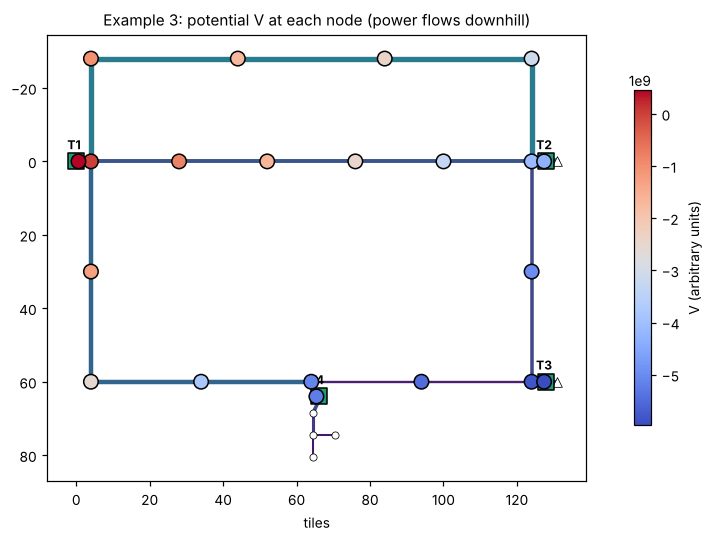

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
m.draw(ax, poles, wires, r, labels=None, colorbar=False, title="Example 3: potential V at each node (power flows downhill)")
nodes = list(r["V"])
v = np.array([r["V"][n] for n in nodes])
sc = ax.scatter([poles[n][0] for n in nodes], [poles[n][1] for n in nodes], c=v, cmap="coolwarm", s=90,
                zorder=7, edgecolor="k")
plt.colorbar(sc, ax=ax, label="V (arbitrary units)", shrink=0.75)
plt.tight_layout()
plt.show()

## What to take away

* Power on transmission divides by resistance: huge poles pull load towards them.
* Losses grow with load: a busy line costs more per megawatt than a light one. Parallel lines
  share the load and cut the loss.
* A chokepoint shows in both views (loading and losses); a bypass relieves both.
* The testbench layouts `/ll-flows` and `/ll-bottleneck` show these numbers live, next to the
  mod's own.